# Exploring PushT

I want to get familiar with the dataset before training anything: what an observation looks like, what the actions represent, and how the demonstrations differ.

Using the project's Python 3.12 `.venv` kernel. The first load downloads the dataset from Hugging Face.

## Setup

Run this once to install the dependencies. Restart the kernel afterwards if any of the packages were already imported.

In [16]:
from pathlib import Path
import importlib.util
import shutil
import subprocess
import sys

repo_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "third_party/lerobot/pyproject.toml").is_file()), None)
if repo_root is None:
    raise FileNotFoundError("Open the notebook inside the repository and initialize third_party/lerobot.")
if sys.version_info[:2] != (3, 12):
    raise RuntimeError("Select the project's Python 3.12 .venv kernel before installing.")
packages = ["-e", f"{repo_root / 'third_party/lerobot'}[dataset,matplotlib-dep]", "ipywidgets"]
if shutil.which("uv"):
    command = ["uv", "pip", "install", "--python", sys.executable]
elif importlib.util.find_spec("pip"):
    command = [sys.executable, "-m", "pip", "install"]
else:
    raise RuntimeError("Install uv or pip, then rerun this cell.")
subprocess.check_call(command + packages)

Using Python 3.12.16 environment at: /home/gbotis/stelios/embodied-ai/.venv
Resolved 107 packages in 681ms
   Building lerobot @ file:///home/gbotis/stelios/embodied-ai/third_party/lerobot
 Downloaded widgetsnbextension
      Built lerobot @ file:///home/gbotis/stelios/embodied-ai/third_party/lerobot
Prepared 4 packages in 547ms
Uninstalled 1 package in 0.40ms
Installed 4 packages in 1ms
 + ipywidgets==8.1.9
 + jupyterlab-widgets==3.0.17
 ~ lerobot==0.6.2 (from file:///home/gbotis/stelios/embodied-ai/third_party/lerobot)
 + widgetsnbextension==4.0.16


0

## Loading the dataset

I'm using `pyav` for the videos because TorchCodec had trouble loading in this environment. I'll start with episode 0; changing `EPISODE_ID` lets me look at another one.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from lerobot.datasets.lerobot_dataset import LeRobotDataset

REPO_ID = "lerobot/pusht"
EPISODE_ID = 0
VIDEO_BACKEND = "pyav"
DATASET_ROOT = None  # Set this if the dataset is already saved locally.
dataset = LeRobotDataset(REPO_ID, root=DATASET_ROOT, video_backend=VIDEO_BACKEND)
print(f"{REPO_ID}: {dataset.num_episodes:,} episodes, {dataset.num_frames:,} frames, {dataset.fps} FPS")
display(pd.DataFrame([
    {"feature": key, "dtype": spec["dtype"], "shape": spec["shape"], "names": spec.get("names")}
    for key, spec in dataset.features.items()
]))

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 509.64it/s]

lerobot/pusht: 206 episodes, 25,650 frames, 10 FPS


,feature,dtype,shape,names
0,observation.image,video,"(96, 96, 3)","[height, width, channel]"
1,observation.state,float32,"(2,)","{'motors': ['motor_0', 'motor_1']}"
2,action,float32,"(2,)","{'motors': ['motor_0', 'motor_1']}"
3,episode_index,int64,"(1,)",None
4,frame_index,int64,"(1,)",None
5,timestamp,float32,"(1,)",None
6,next.reward,float32,"(1,)",None
7,next.done,bool,"(1,)",None
8,next.success,bool,"(1,)",None
9,index,int64,"(1,)",None


## A quick look at the numbers

First, check the episode lengths and look for nonfinite values. I only need the numeric columns here, so there's no reason to decode the images for every frame.

For duration I'm using `(frames - 1) / FPS`, since I'm measuring the time between the first and last frame.

,episode_id,frames,duration_s
count,206.000000,206.000000,206.000000
mean,102.500000,124.514563,12.351456
std,59.611241,35.674371,3.567437
min,0.000000,49.000000,4.800000
25%,51.250000,99.000000,9.800000
50%,102.500000,122.000000,12.100000
75%,153.750000,148.000000,14.700000
max,205.000000,246.000000,24.500000


Finite states: True | Finite actions: True


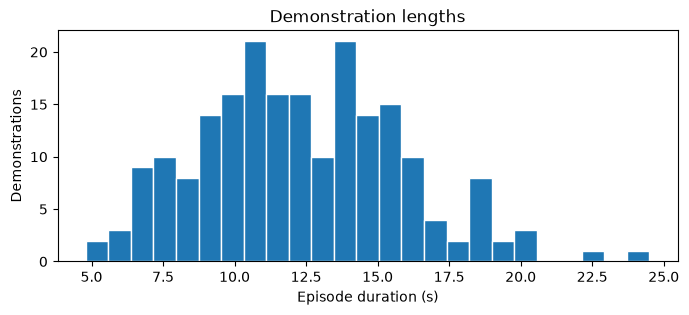

In [18]:
numeric_keys = ["episode_index", "timestamp", "observation.state", "action"]
table = dataset.select_columns(numeric_keys).with_format("numpy")
episode_ids = np.asarray(table["episode_index"]).reshape(-1)
all_states = np.asarray(table["observation.state"])
all_actions = np.asarray(table["action"])
all_timestamps = np.asarray(table["timestamp"]).reshape(-1)
ids, counts = np.unique(episode_ids, return_counts=True)
episode_summary = pd.DataFrame({"episode_id": ids, "frames": counts,
                                "duration_s": (counts - 1) / dataset.fps})
display(episode_summary.describe())
print("Finite states:", np.isfinite(all_states).all(), "| Finite actions:", np.isfinite(all_actions).all())
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(episode_summary["duration_s"], bins=25, edgecolor="white")
ax.set(xlabel="Episode duration (s)", ylabel="Demonstrations", title="Demonstration lengths")
plt.show()

In [19]:
episode_indices = np.flatnonzero(episode_ids == EPISODE_ID)
if not len(episode_indices):
    raise ValueError(f"Episode {EPISODE_ID} is unavailable; choose from {ids.tolist()}.")
states = all_states[episode_indices]
actions = all_actions[episode_indices]
timestamps = all_timestamps[episode_indices] - all_timestamps[episode_indices[0]]
assert np.isfinite(states).all() and np.isfinite(actions).all(), "Nonfinite episode values"
assert np.all(np.diff(timestamps) > 0), "Episode timestamps must increase"
print(f"Episode {EPISODE_ID}: {len(actions)} frames, {timestamps[-1]:.2f} s")
print("State shape:", states.shape, "| Action shape:", actions.shape)
print("Median frame interval:", np.median(np.diff(timestamps)), "s; expected:", 1 / dataset.fps)
sample = dataset[int(episode_indices[0])]
display(pd.DataFrame([{"feature": k, "shape": tuple(v.shape) if hasattr(v, "shape") else None,
                       "type": type(v).__name__} for k, v in sample.items()]))

Episode 0: 161 frames, 16.00 s
State shape: (161, 2) | Action shape: (161, 2)
Median frame interval: 0.09999998 s; expected: 0.1


,feature,shape,type
0,observation.state,"(2,)",Tensor
1,action,"(2,)",Tensor
2,episode_index,(),Tensor
3,frame_index,(),Tensor
4,timestamp,(),Tensor
5,next.reward,(),Tensor
6,next.done,(),Tensor
7,next.success,(),Tensor
8,index,(),Tensor
9,task_index,(),Tensor


## Looking at a few frames

Six frames spread across the selected episode should give me an idea of what's happening. The images have their own pixel coordinates, so I'll keep the state trajectory in a separate plot.

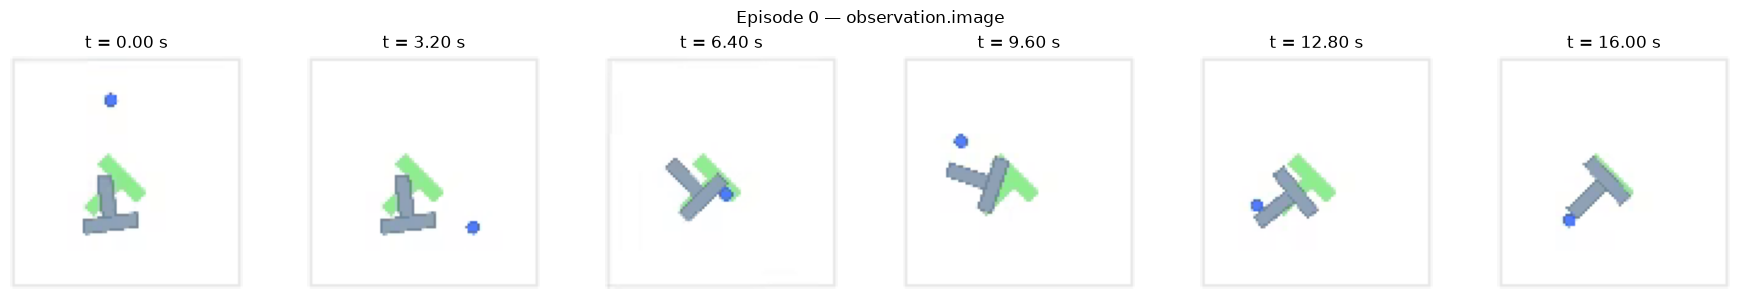

In [20]:
image_keys = [key for key, spec in dataset.features.items() if spec["dtype"] in ("video", "image")]
if not image_keys:
    raise ValueError("This dataset has no image features.")
IMAGE_KEY = image_keys[0]

def to_rgb(value):
    image = value.detach().cpu().numpy() if hasattr(value, "detach") else np.asarray(value)
    if image.ndim == 3 and image.shape[0] in (1, 3, 4):
        image = np.moveaxis(image, 0, -1)
    return np.clip(image, 0, 1) if image.dtype.kind == "f" else image

preview_offsets = np.unique(np.linspace(0, len(episode_indices) - 1, 6, dtype=int))
fig, axes = plt.subplots(1, len(preview_offsets), figsize=(18, 3), squeeze=False)
for ax, offset in zip(axes.flat, preview_offsets):
    ax.imshow(to_rgb(dataset[int(episode_indices[offset])][IMAGE_KEY]))
    ax.set_title(f"t = {timestamps[offset]:.2f} s")
    ax.axis("off")
fig.suptitle(f"Episode {EPISODE_ID} — {IMAGE_KEY}")
plt.tight_layout()
plt.show()

## States and actions

The actions in PushT are target positions for the agent. The state gives the agent's position, not the T-block's pose.

I'll plot both over time and then compare their paths. The distance between them should help me see how closely the agent follows each target. The values are in the dataset's coordinate units.

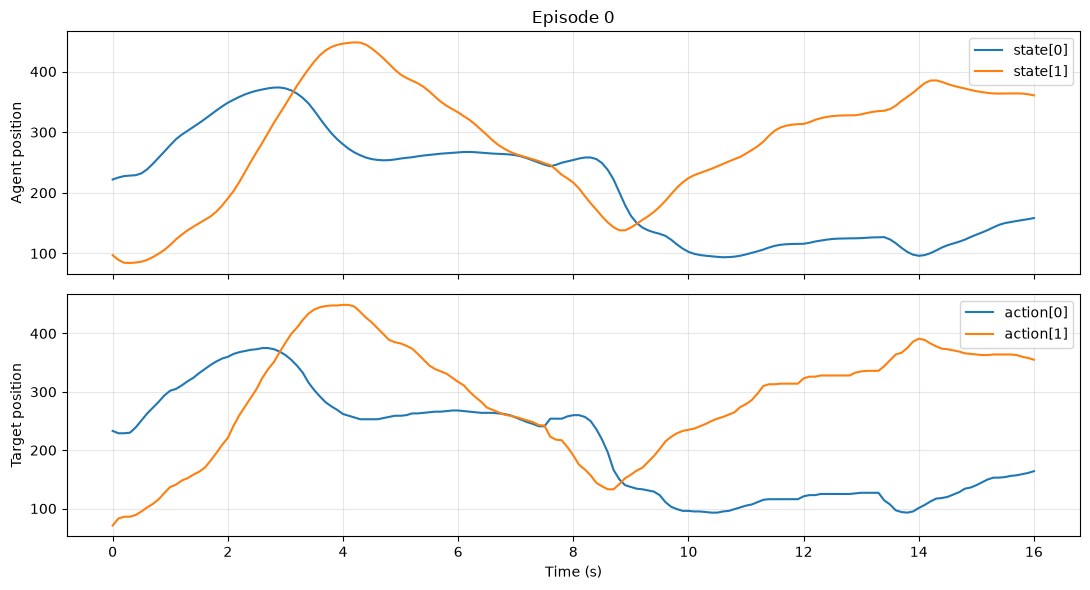

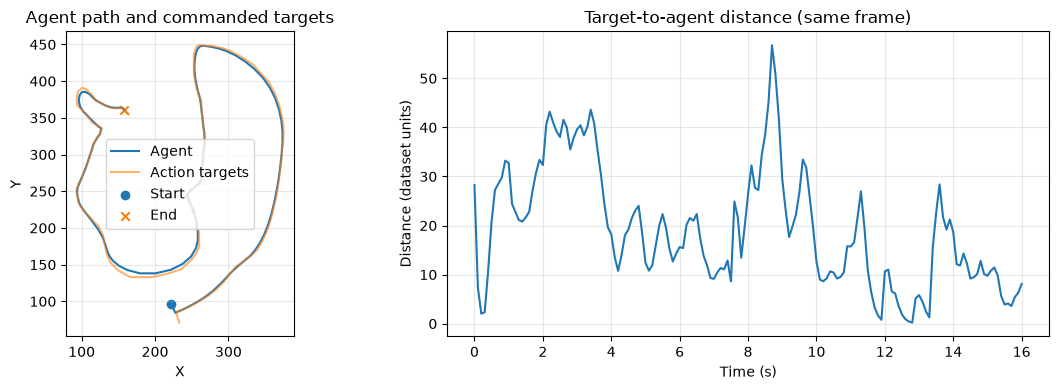

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for dim in range(states.shape[1]):
    axes[0].plot(timestamps, states[:, dim], label=f"state[{dim}]")
for dim in range(actions.shape[1]):
    axes[1].plot(timestamps, actions[:, dim], label=f"action[{dim}]")
axes[0].set(ylabel="Agent position", title=f"Episode {EPISODE_ID}")
axes[1].set(xlabel="Time (s)", ylabel="Target position")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(states[:, 0], states[:, 1], label="Agent")
axes[0].plot(actions[:, 0], actions[:, 1], alpha=0.6, label="Action targets")
axes[0].scatter(*states[0, :2], label="Start")
axes[0].scatter(*states[-1, :2], marker="x", label="End")
axes[0].set(xlabel="X", ylabel="Y", title="Agent path and commanded targets")
axes[0].set_aspect("equal", adjustable="box")
axes[0].legend()
tracking_distance = np.linalg.norm(actions[:, :2] - states[:, :2], axis=1)
axes[1].plot(timestamps, tracking_distance)
axes[1].set(xlabel="Time (s)", ylabel="Distance (dataset units)", title="Target-to-agent distance (same frame)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Comparing a few episodes

I'll pick four episodes spread across the dataset and compare the agent paths. I'll also look at the action distribution across all episodes to get a sense of the range of target positions.

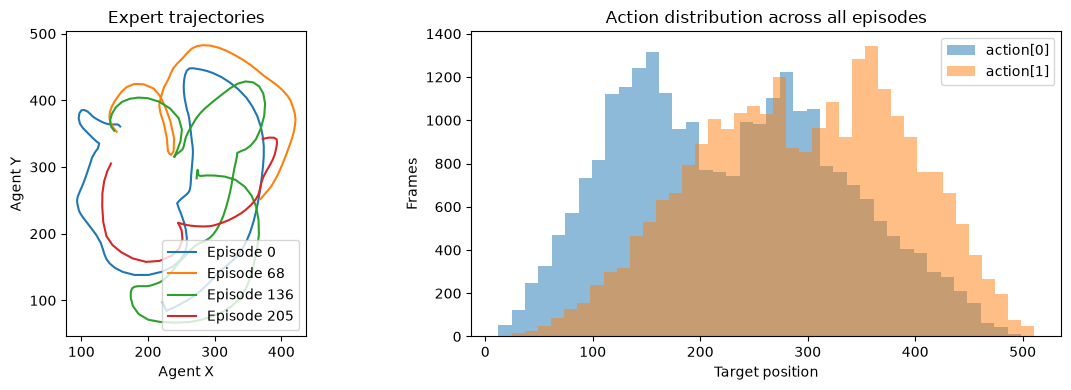

,action[0],action[1]
count,25650.000000,25650.000000
mean,228.239655,293.989075
std,101.601555,96.041168
min,12.000000,25.000000
25%,145.000000,221.000000
50%,226.000000,298.000000
75%,303.000000,369.000000
max,511.000000,511.000000


In [22]:
comparison_ids = ids[np.unique(np.linspace(0, len(ids) - 1, min(4, len(ids)), dtype=int))]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for episode_id in comparison_ids:
    path = all_states[episode_ids == episode_id]
    axes[0].plot(path[:, 0], path[:, 1], label=f"Episode {episode_id}")
axes[0].set(xlabel="Agent X", ylabel="Agent Y", title="Expert trajectories")
axes[0].set_aspect("equal", adjustable="box")
axes[0].legend()
for dim in range(all_actions.shape[1]):
    axes[1].hist(all_actions[:, dim], bins=40, alpha=0.5, label=f"action[{dim}]")
axes[1].set(xlabel="Target position", ylabel="Frames", title="Action distribution across all episodes")
axes[1].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame(all_actions, columns=[f"action[{i}]" for i in range(all_actions.shape[1])]).describe())

## Trying an action chunk

To see what a sequence of training targets might look like, I'll take 16 actions starting at one frame. The chunk stays inside the selected episode.

If there aren't enough actions left, I repeat the last one and mark the extra entries as padding. This is just a small example; the actual training pipeline handles its own sampling.

In [23]:
START_FRAME = 0
HORIZON = 16
if not 0 <= START_FRAME < len(actions) or HORIZON < 1:
    raise ValueError("Choose an existing start frame and a positive horizon.")
valid_actions = actions[START_FRAME:START_FRAME + HORIZON]
valid_length = len(valid_actions)
action_chunk = np.pad(valid_actions, ((0, HORIZON - valid_length), (0, 0)), mode="edge")
action_is_pad = np.arange(HORIZON) >= valid_length
chunk_observation = dataset[int(episode_indices[START_FRAME])]
print("Observation image:", tuple(chunk_observation[IMAGE_KEY].shape))
print("Action chunk:", action_chunk.shape, "| Padding mask:", action_is_pad)
display(pd.DataFrame(action_chunk, columns=[f"action[{i}]" for i in range(actions.shape[1])]).assign(is_pad=action_is_pad))

Observation image: (3, 96, 96)
Action chunk: (16, 2) | Padding mask: [False False False False False False False False False False False False
 False False False False]


,action[0],action[1],is_pad
0,233.0,71.0,False
1,229.0,83.0,False
2,229.0,86.0,False
3,230.0,86.0,False
4,239.0,89.0,False
5,251.0,95.0,False
6,263.0,102.0,False
7,273.0,108.0,False
8,283.0,116.0,False
9,294.0,127.0,False


## Playing part of an episode

A short animation makes the motion easier to follow. I'll use every second frame and cap it at 60 frames to keep the notebook manageable. The playback interval includes the skipped frames.

In [24]:
from matplotlib.animation import FuncAnimation

PLAYBACK_STRIDE = 2
MAX_PLAYBACK_FRAMES = 60
playback_offsets = np.arange(0, len(episode_indices), PLAYBACK_STRIDE)[:MAX_PLAYBACK_FRAMES]
playback_images = [to_rgb(dataset[int(episode_indices[i])][IMAGE_KEY]) for i in playback_offsets]
fig, ax = plt.subplots(figsize=(4, 4))
artist = ax.imshow(playback_images[0])
ax.axis("off")
title = ax.set_title("")

def update(frame):
    artist.set_data(playback_images[frame])
    title.set_text(f"Episode {EPISODE_ID} | t = {timestamps[playback_offsets[frame]]:.2f} s")
    return artist, title

animation = FuncAnimation(fig, update, frames=len(playback_images),
                          interval=1000 * PLAYBACK_STRIDE / dataset.fps, blit=False)
plt.close(fig)
display(HTML(animation.to_jshtml()))

## Things to try next

- Look at a different `EPISODE_ID` and compare the path and target-to-agent distance.
- Set `START_FRAME = len(actions) - 4` to check the padding at the end of an episode.
- Work out which fields would be inputs to an image-based policy and which would be training targets or metadata.
- Keep whole episodes separate when making training and validation splits, so nearby frames from the same demonstration don't end up in both.

The agent path alone doesn't tell me whether the T-block reached the goal. For that I'll need to check the outcome labels or evaluate in the environment.